Your First NN in Pytorch
#Real World Breast Cancer Classification

#Goal:
Build, train, evaluate, visualize a NN in pytorch using breast cancer dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
#Pytorch: Our Deep Learning Framework
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
#random seeds
np.random.seed(42)
torch.manual_seed(42)

In [ ]:
#Load dataset
data= load_breast_cancer()

print(data.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [ ]:
#no of samples and features
print("shape of input data:", data.data.shape)

shape of input data: (569, 30)


In [ ]:
print("Traget Classes:", data.target_names)

Traget Classes: ['malignant' 'benign']


In [ ]:
print(data.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [ ]:
#shape

In [ ]:
# 569 samples 30 features
#create dataframe
df= pd.DataFrame(
    data.data,
    columns=data.feature_names
)
df["target"]= data.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
print("Rows and columns", df.shape)

Rows and columns (569, 31)


In [ ]:
#missing values

In [ ]:
print(df.isnull().sum().sum())

0


In [ ]:
print(df["target"].value_counts())

target
1    357
0    212
Name: count, dtype: int64


In [ ]:
X= df[["mean radius", "mean texture"]].values

In [ ]:
y= df["target"].values
print(X.shape)

(569, 2)


In [ ]:
print(y.shape)

(569,)


In [ ]:
#visualize

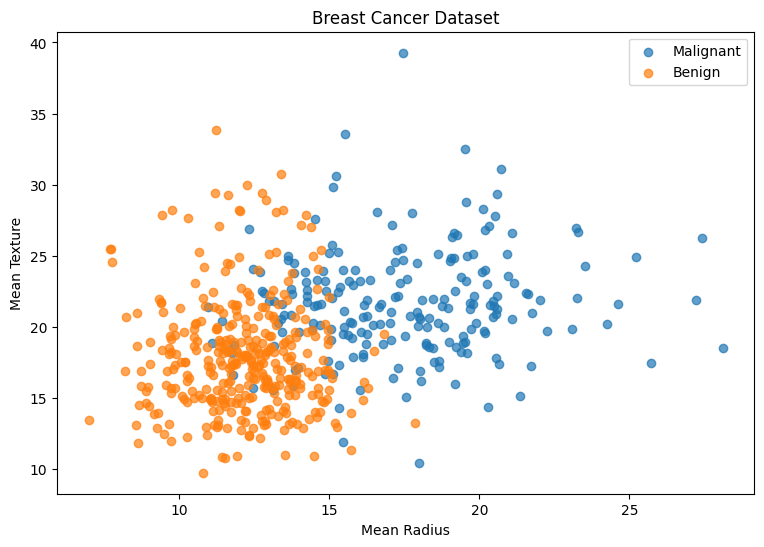

In [ ]:
plt.figure(figsize=(9,6))
plt.scatter(
    X[y==0,0],
    X[y==0,1],
    label= "Malignant",
    alpha= 0.7
)
plt.scatter(
    X[y==1,0],
    X[y== 1,1],
    label= "Benign",
    alpha=0.7
)
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Breast Cancer Dataset")
plt.legend()
plt.show()


In [ ]:
#split data

In [ ]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(364, 2)
(91, 2)
(114, 2)


In [ ]:
print(X_test.shape)

(114, 2)


In [ ]:
#Standardize

In [ ]:
scaler= StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)
X_val_scaled= scaler.transform(X_val)

In [ ]:
#convert Numpy arrays into Pytorch Tensors
X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype= torch.float32
)
X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype= torch.float32
)
X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype= torch.float32
)
y_train_tensor= torch.tensor(
    y_train,
    dtype= torch.float32
).reshape(-1,1)

y_val_tensor= torch.tensor(
    y_val,
    dtype= torch.float32
).reshape(-1,1)

y_test_tensor = torch.tensor(
    y_test,
    dtype= torch.float32
).reshape(-1,1)

print(X_train_tensor.shape)
print(X_test_tensor.shape)
print(y_train_tensor.shape)
print(y_test_tensor.shape)
print(X_val_tensor.shape)
print(y_val_tensor.shape)

torch.Size([364, 2])
torch.Size([114, 2])
torch.Size([364, 1])
torch.Size([114, 1])
torch.Size([91, 2])
torch.Size([91, 1])


In [ ]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)
train_loader= DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)
print(len(train_dataset))
print(len(train_loader))

364
12


In [ ]:
#create NN

class NeuralNetwork(nn.Module):

  def __init__ (self):
    super().__init__()

    self.hidden = nn.Linear(2,8)

    self.output = nn.Linear(8,1)

  def forward(self,x):

    x= self.hidden(x)
    x=torch.relu(x)
    x= self.output(x)
    return x

model = NeuralNetwork()
print(model)


NeuralNetwork(
  (hidden): Linear(in_features=2, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
)


In [ ]:
total_parameters= sum(
    parameter.numel()
    for parameter in model.parameters()
)
print(total_parameters)

33


In [ ]:
for name, parameter in model.named_parameters():
  print(f"{name}: {tuple(parameter.shape)}")

hidden.weight: (8, 2)
hidden.bias: (8,)
output.weight: (1, 8)
output.bias: (1,)


In [ ]:
#try one forward pass before training

with torch.no_grad():
  initial_outputs = model(X_train_tensor[:5])
print (initial_outputs)

tensor([[ 0.1635],
        [-0.5949],
        [ 0.1765],
        [ 0.1176],
        [ 0.0694]])


In [ ]:
#Loss Function

loss_function = nn.BCEWithLogitsLoss()
print(loss_function)

BCEWithLogitsLoss()


In [ ]:
#Adam optimizer
optimizer= torch.optim.Adam(
    model.parameters(),
    lr=0.01
)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


In [ ]:
#train NN
epochs = 100
train_loss_history = []
val_loss_history = []
for epoch in range(epochs):
    # Training phase
    model.train()
    running_train_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(X_batch)

        loss = loss_function(
            predictions,
            y_batch
        )
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * len(X_batch)
    # Average training loss for this epoch
    epoch_train_loss = (
        running_train_loss / len(train_dataset)
    )
    train_loss_history.append(epoch_train_loss)
    # Validation phase
    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_tensor)
        val_loss = loss_function(
            val_logits,
            y_val_tensor
        )
    val_loss_history.append(val_loss.item())
    # Print progress every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:3d}/{epochs} | "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Val Loss: {val_loss.item():.4f}"
        )




Epoch  10/100 | Train Loss: 0.2262 | Val Loss: 0.2389
Epoch  20/100 | Train Loss: 0.2254 | Val Loss: 0.2538
Epoch  30/100 | Train Loss: 0.2245 | Val Loss: 0.2634
Epoch  40/100 | Train Loss: 0.2238 | Val Loss: 0.2712
Epoch  50/100 | Train Loss: 0.2252 | Val Loss: 0.2782
Epoch  60/100 | Train Loss: 0.2242 | Val Loss: 0.2734
Epoch  70/100 | Train Loss: 0.2244 | Val Loss: 0.2795
Epoch  80/100 | Train Loss: 0.2247 | Val Loss: 0.2812
Epoch  90/100 | Train Loss: 0.2238 | Val Loss: 0.2828
Epoch 100/100 | Train Loss: 0.2261 | Val Loss: 0.2906


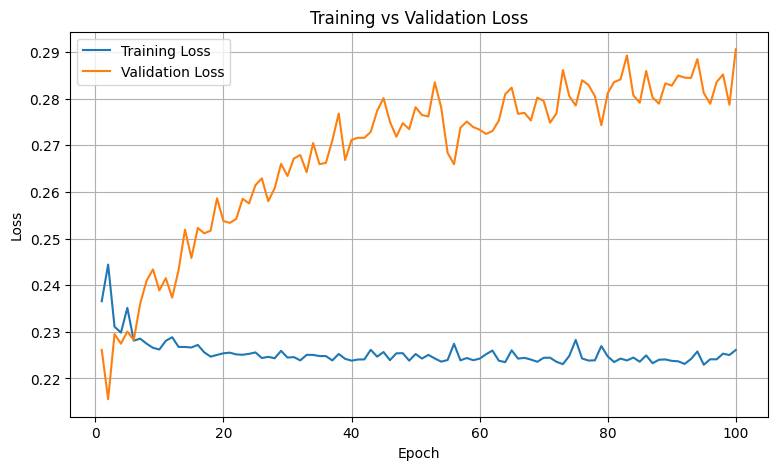

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, epochs + 1),
    train_loss_history,
    label="Training Loss"
)
plt.plot(
    range(1, epochs + 1),
    val_loss_history,
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#evaluate
model.eval()

with torch.no_grad():
  test_logits = model(X_test_tensor)
  test_probabilities = torch.sigmoid(test_logits)

  test_predictions = (
      test_probabilities >= 0.5
  ).float()

  #test accuracy
test_accuracy = (
    test_predictions == y_test_tensor
).float().mean()

print(
    f"test accuracy: {test_accuracy.item() * 100:.2f}%"
)

test accuracy: 86.84%


In [ ]:
#inspect individual predictions
for i in range(min(15, len(y_test))):
  actual= int(y_test[i])
  probability = test_probabilities[i].item()
  predicted = int(test_probabilities[i].item())

  print(
      f"Sample {i+ 1:2d} |"
      f"Actual: {actual} |"
      f"Probability: {probability:.3f} |"
      f"Predicted: {predicted}"
  )

Sample  1 |Actual: 0 |Probability: 0.000 |Predicted: 0
Sample  2 |Actual: 1 |Probability: 0.971 |Predicted: 0
Sample  3 |Actual: 0 |Probability: 0.499 |Predicted: 0
Sample  4 |Actual: 1 |Probability: 0.011 |Predicted: 0
Sample  5 |Actual: 0 |Probability: 0.000 |Predicted: 0
Sample  6 |Actual: 1 |Probability: 0.866 |Predicted: 0
Sample  7 |Actual: 1 |Probability: 0.987 |Predicted: 0
Sample  8 |Actual: 0 |Probability: 0.000 |Predicted: 0
Sample  9 |Actual: 0 |Probability: 0.000 |Predicted: 0
Sample 10 |Actual: 0 |Probability: 0.000 |Predicted: 0
Sample 11 |Actual: 1 |Probability: 0.954 |Predicted: 0
Sample 12 |Actual: 0 |Probability: 0.384 |Predicted: 0
Sample 13 |Actual: 1 |Probability: 0.974 |Predicted: 0
Sample 14 |Actual: 0 |Probability: 0.000 |Predicted: 0
Sample 15 |Actual: 0 |Probability: 0.061 |Predicted: 0


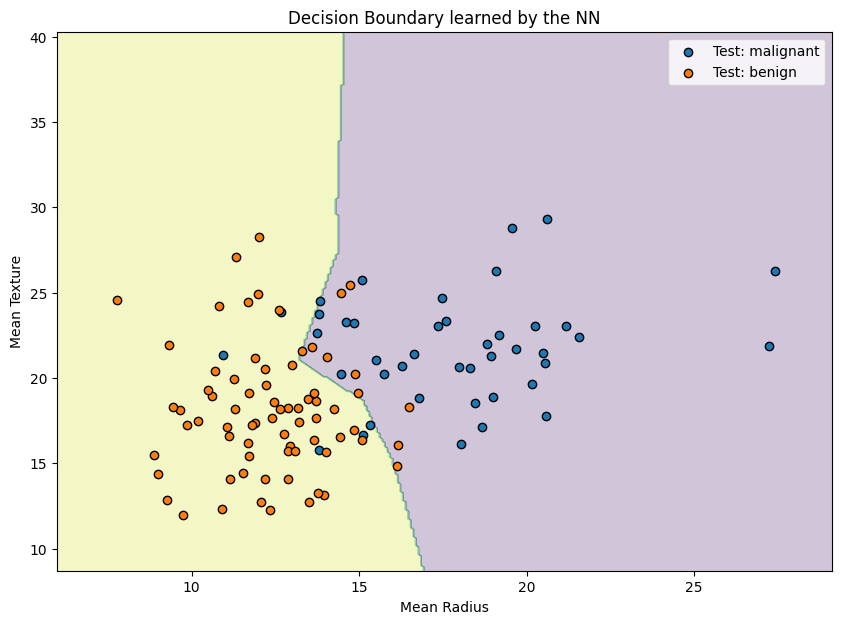

In [ ]:
#visualize decision boundary
model.eval()

x_min, x_max = X[:,0].min()-1, X[:,0].max()+1
y_min, y_max = X[:, 1].min()-1, X[:,1].max()+1

xx,yy= np.meshgrid(
    np.linspace(x_min,x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.c_[
    xx.ravel(),
    yy.ravel()
]

grid_points_scaled= scaler.transform(grid_points)

grid_tensor = torch.tensor(
    grid_points_scaled,
    dtype= torch.float32
)

with torch.no_grad():
  grid_logits = model(grid_tensor)
  grid_probabilities= torch.sigmoid(grid_logits)

grid_predictions = (
    grid_probabilities >=0.5
).float()

grid_predictions = grid_predictions.numpy().reshape(xx.shape)

plt.figure(figsize=(10,7))

plt.contourf(
    xx,
    yy,
    grid_predictions,
    alpha=0.25
)

plt.scatter(
    X_test[y_test == 0,0],
    X_test[y_test == 0,1],
    label= "Test: malignant",
    edgecolor="black"
)
plt.scatter(
    X_test[y_test==1,0],
    X_test[y_test==1,1],
    label= "Test: benign",
    edgecolor="black"
)
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Decision Boundary learned by the NN")
plt.legend()
plt.show()

In [ ]:
#Make predictions for new sample
new_samples= np.array(
    [
        [12.0, 15.0],
        [18.0, 20.0],
        [14.0, 17.0]
    ]
)
new_samples_scaled = scaler.transform(new_samples)

new_tensor = torch.tensor(
    new_samples_scaled,
    dtype=torch.float32
)
model.eval()
with torch.no_grad():
  new_logits= model(new_tensor)
  new_probabilities= torch.sigmoid(
      new_logits
  )
  new_predictions = (new_probabilities >=0.5).float()
for i in range(len(new_samples)):
  probability = new_probabilities[i].item()
  predicted_class= int(new_predictions[i].item())
  class_name= (
      "Malignant " if predicted_class == 0
      else "benign"
  )

  print(
      f"Sample {i+1}:"
      f"Features= {new_samples[i]} |"
      f"Probability = {probability:.3f} | "
      f"predicted Class= {predicted_class} ({class_name})"
  )

Sample 1:Features= [12. 15.] |Probability = 0.968 | predicted Class= 1 (benign)
Sample 2:Features= [18. 20.] |Probability = 0.000 | predicted Class= 0 (Malignant )
Sample 3:Features= [14. 17.] |Probability = 0.881 | predicted Class= 1 (benign)
